In [10]:
import math
import random
import json
from copy import deepcopy

from shapely.geometry import Polygon, box
from shapely.affinity import translate
from shapely.ops import unary_union

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection

import os
import re
import numpy as np

from svgpathtools import svg2paths2
from collections import defaultdict


from shapely.geometry import Polygon as ShapelyPolygon, MultiPolygon, box
from shapely.affinity import translate, rotate
from shapely.ops import unary_union
from shapely.geometry import box
from shapely.affinity import translate

In [11]:
class MarkerMemory:
    def __init__(self):
        self.best_layout = None
        self.best_score = float("inf")
        self.top_layouts = []
        self.history = []

    def score(self, shapes, strip_width):
        items = []
        for s in shapes:
            coords = list(s.poly.exterior.coords)
            items.append({"polygon": coords})

        k = evaluate_kpis(items, strip_width)

        # industrial score
        score = k["layer_length_in"] + (k["empty_ratio"] * 50)

        return score, k

    def update(self, shapes, strip_width, iter_id, save_folder):
        score, kpis = self.score(shapes, strip_width)

        self.history.append({
            "iter": iter_id,
            "score": score,
            "kpis": kpis
        })

        improved = False

        if score < self.best_score:
            self.best_score = score
            self.best_layout = deepcopy(shapes)
            improved = True

        # maintain top 5
        self.top_layouts.append((score, deepcopy(shapes)))
        self.top_layouts.sort(key=lambda x: x[0])
        self.top_layouts = self.top_layouts[:5]

        if improved:
            print(f"\n🔥 IMPROVED @ iter {iter_id}")
            print(f"Height: {kpis['layer_length_in']:.3f}")
            print(f"Empty:  {kpis['empty_ratio']:.3f}")

            path = os.path.join(save_folder, f"best_iter_{iter_id}.png")
            render_layout(shapes, STRIP_WIDTH,
                          f"Best Iter {iter_id}",
                          path)

        return improved


In [19]:
def extract_color(attr):
    """
    Extract fill or stroke color from SVG attributes.
    Supports hex and rgb() styles from CorelDRAW.
    """

    # Direct attributes
    if attr.get("fill") and attr["fill"] != "none":
        return attr["fill"]

    if attr.get("stroke") and attr["stroke"] != "none":
        return attr["stroke"]

    style = attr.get("style", "")

    # Hex colors
    m = re.search(r"fill:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    m = re.search(r"stroke:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    # rgb() colors (Corel)
    m = re.search(r"(fill|stroke):\s*rgb\([^)]+\)", style)
    if m:
        return m.group(0)  # use full rgb(...) string as key

    return None
    
def parse_filename(filename):
    """
    JB_FRONT_16-18-20.svg  → sizes = ['16','18','20']
    JB_FRONT_M-L-XL.svg    → sizes = ['M','L','XL']
    """

    name = os.path.splitext(filename)[0]

    parts = name.split("_")
    if len(parts) < 3:
        raise ValueError(f"Invalid filename format: {filename}")

    brand = parts[0]
    part = parts[1].upper()
    size_list = parts[2]

    sizes = size_list.split("-")

    return part, sizes

def svg_path_to_polygon(path, svg_attr, samples=40):
    # --- Parse viewBox ---
    vb_x, vb_y, vb_w, vb_h = map(float, svg_attr["viewBox"].split())

    # --- Parse physical size in mm ---
    width_mm = float(svg_attr["width"].replace("mm", ""))
    height_mm = float(svg_attr["height"].replace("mm", ""))

    scale_x = width_mm / vb_w
    scale_y = height_mm / vb_h

    raw = []
    for seg in path:
        for t in np.linspace(0, 1, samples):
            pt = seg.point(t)
            raw.append((pt.real, pt.imag))

    # Convert to inches
    pts = []
    for x, y in raw:
        x_mm = (x - vb_x) * scale_x
        y_mm = (y - vb_y) * scale_y
        pts.append((x_mm / 25.4, y_mm / 25.4))

    # Flip Y and normalize
    max_y = max(y for _, y in pts)
    pts = [(x, max_y - y) for x, y in pts]

    min_x = min(x for x, _ in pts)
    min_y = min(y for _, y in pts)
    pts = [(x - min_x, y - min_y) for x, y in pts]

    return pts

def load_svg_file(svg_path):
    paths, attrs, svg_attr = svg2paths2(svg_path)

    colored_groups = defaultdict(list)
    uncolored_paths = []

    for path, attr in zip(paths, attrs):
        color = extract_color(attr)
        if color is None:
            uncolored_paths.append(path)
        else:
            colored_groups[color].append(path)

    polygons = []

    # --- Case 1: color-based grouping ---
    if colored_groups:
        for color, group in colored_groups.items():
            pts = []
            for p in group:
                pts.extend(svg_path_to_polygon(p, svg_attr))

            poly = ShapelyPolygon(pts)

            if poly.area > 1e-3:
                polygons.append(poly)

    # --- Case 2: fallback (no colors) ---
    else:
        for p in paths:
            pts = svg_path_to_polygon(p, svg_attr)
            poly = ShapelyPolygon(pts)

            if poly.area > 1e-3:
                polygons.append(poly)
    
    if not polygons:
        raise ValueError(f"No valid polygons found in {svg_path}")

    return polygons
    
def process_design_folder(folder_path):
    all_shapes = []

    for file in os.listdir(folder_path):
        if not file.lower().endswith(".svg"):
            continue

        part, sizes = parse_filename(file)
        svg_path = os.path.join(folder_path, file)

        polygons = load_svg_file(svg_path)
        
        sized_polys = assign_sizes(polygons, sizes)
        
        for size, poly in sized_polys:
            all_shapes.append({
                "part": part,
                "size": size,
                "polygon": poly
            })
    
    # Save structured output
    out_path = os.path.join(folder_path, "parsed_shapes.json")
    with open(out_path, "w") as f:
        json.dump(all_shapes, f, indent=2)

    return all_shapes            

def assign_sizes(polygons, sizes):
    assert len(polygons) == len(sizes), (
        f"Size count mismatch: {len(polygons)} polygons vs {len(sizes)} sizes"
    )

    areas = [(poly.area, poly) for poly in polygons]
    areas.sort(key=lambda x: x[0])  # smallest → largest
    validate_monotonic_areas(polygons)
    result = []
    for size, (_, poly) in zip(sizes, areas):
        result.append((size, list(poly.exterior.coords)))

    return result

def validate_monotonic_areas(polygons):
    areas = sorted(poly.area for poly in polygons)
    for i in range(len(areas) - 1):
        ratio = areas[i + 1] / areas[i]
        if ratio < 1.02:
            raise ValueError(
                "Two sizes have nearly identical area. "
                "Check colors or duplicate patterns."
            )

def extract_polygons(shape_items):
    """
    Converts process_design_folder() output
    into pure shapely polygon list.
    """
    polys = []

    for item in shape_items:
        poly = item["polygon"]

        # Already shapely polygon → OK
        if hasattr(poly, "bounds"):
            polys.append(poly)
        else:
            # If stored as point list
            polys.append(Polygon(poly))

    return polys
    
def layout_to_kpi_items(polys):
    """
    Convert shapely polygon list into
    format expected by evaluate_kpis()
    """
    items = []

    for p in polys:
        coords = list(p.exterior.coords)
        items.append({
            "polygon": coords
        })

    return items
    
def evaluate_kpis(placed_shapes, strip_width):
    max_y = 0.0
    used_area = 0.0

    for item in placed_shapes:
        poly = item["polygon"]

        for _, y in poly:
            max_y = max(max_y, y)

        area = 0.0
        n = len(poly)
        for i in range(n):
            x1, y1 = poly[i]
            x2, y2 = poly[(i + 1) % n]
            area += (x1 * y2 - x2 * y1)
        used_area += abs(area) / 2.0

    total_area = strip_width * max_y
    empty_ratio = 1.0 - (used_area / total_area) if total_area > 0 else 0.0

    return {
        "layer_length_in": max_y,
        "used_area_in2": used_area,
        "total_area_in2": total_area,
        "empty_ratio": empty_ratio
    }

def convert_for_kpi(placed_shapes):
    kpi_items = []

    for s in placed_shapes:
        coords = list(s.poly.exterior.coords)
        kpi_items.append({
            "part": s.part,
            "size": s.size,
            "polygon": coords
        })

    return kpi_items


def build_shapes(shape_items):
    shapes = []
    for item in shape_items:
        poly = item["polygon"]
        if not hasattr(poly, "bounds"):
            poly = Polygon(poly)

        shapes.append(
            Shape(item["part"], item["size"], poly)
        )
    return shapes



class Shape:
    def __init__(self, part, size, poly):
        self.part = part
        self.size = size
        self.poly = poly

    def area(self):
        return self.poly.area

    def copy(self):
        return Shape(self.part, self.size,
                     Polygon(self.poly.exterior.coords))

def place_shape(shape, x, y):
    minx, miny, maxx, maxy = shape.poly.bounds
    moved = translate(shape.poly,
                      xoff=x - minx,
                      yoff=y - miny)
    return Shape(shape.part, shape.size, moved)

def intersects_any(test_shape, placed):
    for p in placed:
        if test_shape.poly.intersects(p.poly):
            return True
    return False

In [16]:
def render_marker(shapes, strip_width, title="Marker", save=None):

    fig, ax = plt.subplots(figsize=(6, 12))
    patches = []

    for s in shapes:
        coords = list(s.poly.exterior.coords)
        patches.append(MplPolygon(coords))

        cx, cy = s.poly.centroid.x, s.poly.centroid.y
        ax.text(cx, cy, f"{s.part}-{s.size}",
                ha='center', va='center', fontsize=7)

    pc = PatchCollection(
        patches,
        facecolor="#dddddd",
        edgecolor="black",
        linewidth=1
    )
    ax.add_collection(pc)

    max_y = max(s.poly.bounds[3] for s in shapes)

    ax.set_xlim(0, strip_width)
    ax.set_ylim(max_y, 0)
    ax.set_title(title)
    ax.set_aspect("equal")

    if save:
        folder = os.path.dirname(save)
        if folder and not os.path.exists(folder):
            os.makedirs(folder, exist_ok=True)

        plt.savefig(save, dpi=150, bbox_inches="tight")

    plt.show()

In [17]:
def simple_vertical_stack(shapes, strip_width):
    y = 0
    placed = []

    for s in shapes:
        poly = s.poly
        minx, miny, maxx, maxy = poly.bounds

        moved = translate(poly, xoff=0 - minx, yoff=y - miny)
        new_shape = Shape(s.part, s.size, moved)

        placed.append(new_shape)
        y += (maxy - miny) + 0.2

    return placed


def build_baseline_marker(shape_items, strip_width, gap=0.15):

    shapes = build_shapes(shape_items)

    # sort by area (largest first)
    shapes.sort(key=lambda s: s.area(), reverse=True)

    remaining = shapes[:]
    placed = []

    y_cursor = 0

    while remaining:

        x_cursor = 0
        row_height = 0
        placed_this_row = True

        # keep filling row until nothing fits
        while placed_this_row:
            placed_this_row = False

            # try all remaining shapes (largest first)
            for s in remaining:
                minx, miny, maxx, maxy = s.poly.bounds
                w = maxx - minx
                h = maxy - miny

                if x_cursor + w > strip_width:
                    continue

                candidate = place_shape(s, x_cursor, y_cursor)

                if intersects_any(candidate, placed):
                    continue

                # place it
                placed.append(candidate)
                remaining.remove(s)

                x_cursor += w + gap
                row_height = max(row_height, h)
                placed_this_row = True
                break

        # move up to next row
        if row_height == 0:
            # nothing fit, force place largest
            s = remaining.pop(0)
            forced = place_shape(s, 0, y_cursor)
            placed.append(forced)
            _, _, _, h = forced.poly.bounds
            row_height = h

        y_cursor += row_height + gap

    return placed



BASELINE KPIs:
layer_length_in: 47.072
used_area_in2: 1271.603
total_area_in2: 1694.606
empty_ratio: 0.250


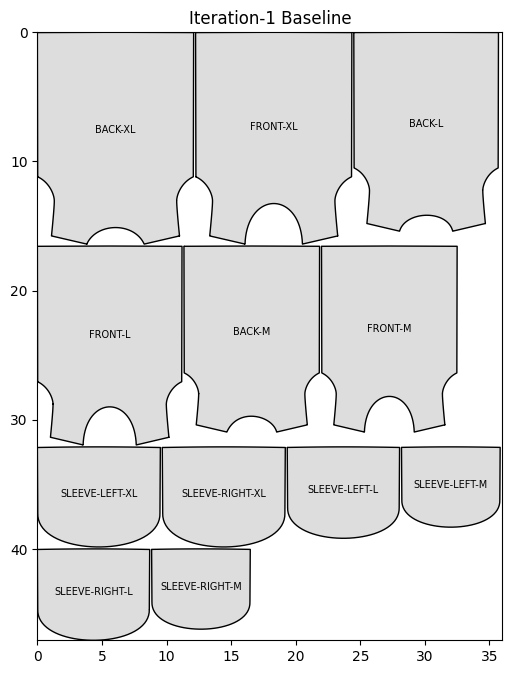

In [20]:
STRIP_WIDTH = 36
design_folder = "JK-123"

shape_items = process_design_folder(design_folder)

baseline = build_baseline_marker(shape_items, STRIP_WIDTH)

kpi_ready = convert_for_kpi(baseline)

kpis = evaluate_kpis(kpi_ready, STRIP_WIDTH)

print("\nBASELINE KPIs:")
for k, v in kpis.items():
    print(f"{k}: {v:.3f}")

render_marker(baseline, STRIP_WIDTH,
              "Iteration-1 Baseline",
              save="JK-123/v14/baseline.png")
